# Concept annotation coverage and MERMAID-style thresholds

Questions:

1. How many concepts have **no annotations at all** in the data we have (train, val and test splits)? An annotation
   counts for a concept only if the concept is **True** for the annotated label, i.e. value `2` in the
   `ConceptSchema` encoding (`TRUE` for binary concepts, the label's own value for a taxonomic rank). `FALSE` and
   `not_given` do not count.
2. Which thresholds were used to pick the MERMAID label set (`class_subset`), and are they
   *at least 100 images, at least 500 annotations, at least 3 sources*?
3. How many concepts would be **removed** if the same thresholds were applied to concepts?

Questions 1 and 3 are answered separately for **taxonomic** concepts (`rank__value` channels, e.g. `genus__acropora`)
and **binary** concepts (morphology, health and non-coral channels).

The binary concepts include `rubble`, `water surface` and `water column`. They are columns of the concept table but
not yet channels of the current model code (`NONCORAL_CONCEPTS` lacks them). They are planned for the next training
code, so they are analysed like the other binary concepts and flagged `in_current_model = False`.

This notebook only reads data. It changes no configs or code.

## Setup

Data used:

- `dataset_stats/all_label_counts_final_768.parquet`: one row per `(dataset, split, image, source label)` for **every
  configured split** (train, val, test) of `data_config_final_768.yaml`. It is built the same way as
  `scripts/train_label_counts.py` (same functions, same cached data, image blacklist and annotation overrides applied),
  just without the train-only restriction. `n` is the number of points for sparse datasets and the number of pixels for
  dense ones.
- The CoralNet training manifest (local S3 cache), used to look up each CoralNet image's `source_id`.
- The concept table (`CONCEPT_CSV`), loaded through `ConceptSchema.from_csv`, the same way `scripts/train.py` does.

Definitions:

- **Source**: for CoralNet this is the CoralNet `source_id`, the unit the MERMAID label selection used. Every other
  dataset (MERMAID, Catlin Seaview, Moorea, Pacific Labeled Corals, Benthos, Coralscapes v2, UCSD mosaics) counts as
  one source.
- **Source rule for concepts** (adapted from the MERMAID rule's ">= 3 sources"): a concept passes if it appears in
  **at least one non-CoralNet dataset**, or, if CoralNet is its only dataset, in **at least 3 CoralNet sources**. The
  annotation threshold (>= 500) is unchanged. Section 4 compares this with the plain
  ">= 3 sources" rule.
- **Image rule for concepts**: a concept passes if it appears in **at least 100 images in total, or at least 50 images
  outside CoralNet** (`MIN_NONCORALNET_IMAGES`).
- **Annotation**: one point for sparse datasets. Dense masks have no points, so `DENSE_ANNOTATION_UNIT` sets how they
  are counted. The default `"mask"` counts **each dense mask that contains the concept as 50 annotations**
  (`DENSE_ANNOTATIONS_PER_MASK`), once per (mask, concept). Section 5 shows how
  the results change with the other options.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
import yaml

from mermaidseg.dataset_reconciliation.concept_schema import ConceptSchema
from mermaidseg.dataset_reconciliation.concepts import TAXONOMIC_CONCEPTS

pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

REPO = Path.cwd().parent if Path.cwd().name == "nbs" else Path.cwd()
CACHE = Path("/archive/vision/beery/red_sea_coral/cache_MERMAID")
FINAL_REPO = Path("/data/vision/beery/scratch/sauder/mermaid-segmentation-final")

LABEL_COUNTS = REPO / "dataset_stats/all_label_counts_final_768.parquet"
CORALNET_MANIFEST = (CACHE / "dev-datamermaid-sm-sources/etl-outputs/coralnet/20260623_nogit/"
                     "coralnet_training_manifest_20260623_nogit.parquet")
CONCEPT_CSV = REPO / "configs/class_to_concepts.csv"

# Dataset sources that are part of the run (data_config_final_768.yaml, non-None blocks). This matches
# `run_sources` in scripts/train.py, so the concept channels are the ones the model has.
RUN_SOURCES = {"coralnet", "mermaid", "coralscapes_v2", "benthos_yuval", "catlin_seaview",
               "moorea_labeled_corals", "pacific_labeled_corals", "ucsd_mosaics"}
DENSE_DATASETS = {"coralscapes_v2", "ucsd_mosaics", "benthos_yuval"}
DENSE_ANNOTATION_UNIT = "mask"  # "mask" | "pixels" | "exclude"
DENSE_ANNOTATIONS_PER_MASK = 50  # with "mask": annotations credited per dense mask that contains the concept

# Concept-table columns that are not channels in the current code but will be added in the next training code.
EXTRA_BINARY_CONCEPTS = ["rubble", "water surface", "water column"]

MIN_IMAGES, MIN_ANNOTATIONS, MIN_SOURCES = 100, 500, 3  # MIN_SOURCES: original MERMAID-label rule (section 1)
# Source rule for concepts: the concept must appear in at least one non-CoralNet dataset, or, if CoralNet is its only
# dataset, in at least MIN_CORALNET_SOURCES CoralNet sources.
MIN_CORALNET_SOURCES = 3
# Image rule for concepts: >= MIN_IMAGES images in total, or >= MIN_NONCORALNET_IMAGES images outside CoralNet.
MIN_NONCORALNET_IMAGES = 50

## 1. Which thresholds were used for the MERMAID labels?

The MERMAID label set was chosen in
[`mermaidseg/datasets/coralnet/nbs/coralnet_subsetting_eda.ipynb`](../mermaidseg/datasets/coralnet/nbs/coralnet_subsetting_eda.ipynb).
The steps were:

1. Load CoralNet annotations (`coralnet_training_resized_20260526_807b611.parquet`).
2. Keep sources with **more than 100 images and at least 1000 annotations** (cell 17), then keep only the sources
   marked `ToKeep == "Yes"` in a manual quality sheet (`coralnet_source_quality.csv`, cell 21).
3. Map CoralNet labels to MERMAID labels and save the mapping as `configs/coralnet_to_mermaid_mapping_temporary.json`.
4. "Final label subsetting" (cell 70):

```python
num_images_threshold = 100
num_annotations_threshold = 500
num_sources_threshold = 3
df_labels_subset = df_labels[(num_annotations >= 500) * (num_images >= 100) * (num_sources >= 3)]
```

`df_labels` holds, per MERMAID label, the number of annotations (points), unique images and unique CoralNet
`source_id`s. So the thresholds are **>= 100 images, >= 500 annotations, >= 3 sources**, all inclusive. The resulting
list became `class_subset` in the training configs.

The saved notebook has no outputs, so the check below recomputes the result. The quality sheet is only on S3, which is
not reachable from here. The check therefore applies step 2 without the quality filter (if S3 is reachable it is used)
and compares the labels that pass with `class_subset`.

In [2]:
import json

C = CACHE / "dev-datamermaid-sm-sources"
cn = pd.read_parquet(C / "etl-outputs/coralnet/20260526_807b611/coralnet_training_resized_20260526_807b611.parquet",
                     columns=["source_id", "image_id", "coralnet_id"])
id2name = json.load(open(C / "coralnet-public-images/temporary/coralnet_id2name.json"))
cn_to_mermaid = json.load(open(REPO / "configs/coralnet_to_mermaid_mapping_temporary.json"))

src = cn.groupby("source_id").agg(n_images=("image_id", "nunique"), n_ann=("image_id", "size"))
keep_sources = set(src.index[(src.n_images > 100) & (src.n_ann >= 1000)])
quality_filter_applied = False
try:
    q = pd.read_csv("s3://dev-datamermaid-sm-sources/coralnet-public-images/temporary/coralnet_source_quality.csv")
    keep_sources &= set(q.loc[q["ToKeep"] == "Yes", "Source ID"])
    quality_filter_applied = True
except Exception as e:  # noqa: BLE001
    print(f"Quality sheet not available ({type(e).__name__}); skipping the manual source-quality filter.")
cn = cn[cn.source_id.isin(keep_sources)]
cn["mermaid_label"] = cn.coralnet_id.astype(str).map(id2name).astype(str).str.lower().map(cn_to_mermaid)
print(f"{len(keep_sources)} sources, {len(cn):,} annotations, quality filter applied: {quality_filter_applied}")

mermaid_label_stats = (cn.dropna(subset=["mermaid_label"]).groupby("mermaid_label")
                       .agg(num_annotations=("image_id", "size"), num_images=("image_id", "nunique"),
                            num_sources=("source_id", "nunique")))
mermaid_label_stats["passes"] = ((mermaid_label_stats.num_annotations >= MIN_ANNOTATIONS)
                                 & (mermaid_label_stats.num_images >= MIN_IMAGES)
                                 & (mermaid_label_stats.num_sources >= MIN_SOURCES))
del cn

/data/vision/beery/scratch/viktordo/mermaid-segmentation/.venv/lib/python3.12/site-packages/fsspec/registry.py:301: UserWarning: Your installed version of s3fs is very old and known to cause
severe performance issues, see also https://github.com/dask/dask/issues/10276

To fix, you should specify a lower version bound on s3fs, or
update the current installation.

  warnings.warn(s3_msg)


Quality sheet not available (PermissionError); skipping the manual source-quality filter.


486 sources, 19,292,978 annotations, quality filter applied: False


In [3]:
cfg_candidates = [REPO / "configs/training_config_cbm_scratch100k.yaml", FINAL_REPO / "configs/training_config_cbm_final.yaml"]
cfg_found = [p for p in cfg_candidates if p.exists()]
subsets = {p: yaml.safe_load(open(p))["training"]["class_subset"] for p in cfg_found}
class_subset = subsets[cfg_found[0]]
print("class_subset read from:", [str(p) for p in cfg_found])
print("identical across these configs:", len({frozenset(v) for v in subsets.values()}) == 1)

cs = {c.lower() for c in class_subset}
passing = {l.lower() for l in mermaid_label_stats.index[mermaid_label_stats.passes]}
print(f"class_subset: {len(cs)} labels | pass 100/500/3 in the reproduction: {len(passing)} | in both: {len(cs & passing)}")
print("In class_subset but not passing (or not a CoralNet target):", sorted(cs - passing))
print("Passing but not in class_subset:", sorted(passing - cs))

extra = mermaid_label_stats.loc[[l for l in mermaid_label_stats.index if l.lower() in passing - cs]]
extra.sort_values("num_annotations", ascending=False)

class_subset read from: ['/data/vision/beery/scratch/viktordo/mermaid-segmentation/configs/training_config_cbm_scratch100k.yaml', '/data/vision/beery/scratch/sauder/mermaid-segmentation-final/configs/training_config_cbm_final.yaml']
identical across these configs: True
class_subset: 78 labels | pass 100/500/3 in the reproduction: 94 | in both: 77
In class_subset but not passing (or not a CoralNet target): ['human']
Passing but not in class_subset: ['acropora cervicornis', 'acropora palmata', 'agaricia', 'agaricia tenuifolia', 'anemone', 'colpophyllia natans', 'diploria labyrinthiformis', 'herpolitha', 'madracis decactis', 'meandrina meandrites', 'orbicella franksi', 'other coral bleached', 'other coral dead', 'plesiastrea', 'silt', 'stephanocoenia intersepta', 'tubipora']


,num_annotations,num_images,num_sources,passes
mermaid_label,,,,
Silt,27219,1916,18,True
Acropora cervicornis,17104,1349,23,True
Other coral bleached,11047,1462,4,True
Other coral dead,7337,1619,4,True
Colpophyllia natans,5220,1469,31,True
Orbicella franksi,2396,804,24,True
Agaricia tenuifolia,1987,520,9,True
Anemone,1465,343,40,True
Acropora palmata,1164,143,13,True


**Conclusion.** Every `class_subset` label that is a CoralNet target passes the 100 / 500 / 3 rule. The only
exception, `human`, is not a target in the CoralNet mapping at all; it was added by hand. The extra labels that pass
here are mostly Caribbean species, plus `other coral bleached/dead`, `silt` and `anemone`. They are expected to drop
out once the manual source-quality filter is applied, since that filter is the one step this reproduction cannot
perform. So the thresholds are as stated: **>= 100 images, >= 500 annotations, >= 3 (CoralNet) sources**, computed
per label on CoralNet points.

## 2. Concept annotation counts on all data

In [4]:
counts = pd.read_parquet(LABEL_COUNTS)
counts["image_id"] = counts.image_id.astype(str)

# CoralNet image -> source_id
man = pd.read_parquet(CORALNET_MANIFEST, columns=["source_id", "image_id"]).drop_duplicates("image_id")
img2src = dict(zip(man.image_id.astype(str), man.source_id.astype(str)))
del man
is_cn = counts.dataset == "coralnet"
counts["source"] = counts.dataset
counts.loc[is_cn, "source"] = "coralnet:" + counts.loc[is_cn, "image_id"].map(img2src)
print("CoralNet rows without a source_id:", counts.loc[is_cn, "source"].isna().sum())

counts.groupby(["dataset", "split"]).agg(images=("image_id", "nunique"), labels=("label", "nunique"),
                                         sources=("source", "nunique"), n=("n", "sum"))

CoralNet rows without a source_id: 0


images  labels  sources           n
dataset                split                                     
benthos_yuval          val        48       8        1   216236375
catlin_seaview         train   11357     193        1      858370
coralnet               test    51026    1175      144     1511187
                       train  463597    2885      597    14015278
coralscapes_v2         test      473      84        1   843144589
                       train    1960      95        1  3587428366
mermaid                train   15208     243        1      380200
moorea_labeled_corals  train    2002      29        1      386441
pacific_labeled_corals val      4419      20        1      155788
ucsd_mosaics           train    4670      34        1   684990454

In [5]:
df_csv = pd.read_csv(CONCEPT_CSV)
df_csv["source_dataset_source"] = df_csv.source_dataset_source.astype(str).str.lower()
df_csv["source_label_class_name"] = df_csv.source_label_class_name.astype(str).str.lower()
df_csv = df_csv[df_csv.source_dataset_source.isin(RUN_SOURCES)].drop_duplicates(
    ["source_dataset_source", "source_label_class_name"])


def build_concepts(csv_path: Path):
    # Model channels from ConceptSchema plus EXTRA_BINARY_CONCEPTS read from the CSV (TRUE = annotated).
    schema = ConceptSchema.from_csv(csv_path, sources=RUN_SOURCES)
    csv = pd.read_csv(csv_path)
    csv["source_dataset_source"] = csv.source_dataset_source.astype(str).str.lower()
    csv["source_label_class_name"] = csv.source_label_class_name.astype(str).str.lower()
    csv = csv[csv.source_dataset_source.isin(RUN_SOURCES)].drop_duplicates(
        ["source_dataset_source", "source_label_class_name"]).set_index(
        ["source_dataset_source", "source_label_class_name"])
    extras = [c for c in EXTRA_BINARY_CONCEPTS if c in csv.columns and c not in schema.channel_names]
    extra_true = {c: csv[c].astype(str).str.upper().eq("TRUE") for c in extras}
    channels = list(schema.channel_names) + extras
    info = pd.DataFrame({
        "kind": ["taxonomic" if "__" in c else "binary" for c in channels],
        "in_current_model": [c in schema.channel_names for c in channels],
    }, index=channels)

    def matrix(pairs) -> sp.csr_matrix:
        # Boolean (len(pairs), n_channels) matrix: concept is True for the (dataset, label) pair.
        base = np.stack([schema.row_for(d, l) for d, l in pairs]) == 2
        ext = np.array([[bool(extra_true[c].get((d, l), False)) for c in extras] for d, l in pairs],
                       dtype=bool).reshape(len(pairs), len(extras))
        return sp.csr_matrix(np.hstack([base, ext]).astype(np.int64))

    return schema, channels, info, matrix


schema, channels, info, concept_matrix = build_concepts(CONCEPT_CSV)
print(f"Concept table: {CONCEPT_CSV.name}")
print(pd.crosstab(info.kind, info.in_current_model, margins=True))

# One row per unique (dataset, label) key.
keys = counts[["dataset", "label"]].drop_duplicates().reset_index(drop=True)
key_pairs = list(keys.itertuples(index=False, name=None))
key_idx = pd.Series(np.arange(len(keys)), index=pd.MultiIndex.from_frame(keys))
counts["key"] = key_idx.loc[pd.MultiIndex.from_frame(counts[["dataset", "label"]])].to_numpy()
K = concept_matrix(key_pairs)

in_schema = np.array([p in schema.row_by_key for p in key_pairs])
unmapped = counts[~in_schema[counts.key]]
print(f"(dataset, label) keys not in the concept table: {(~in_schema).sum()} of {len(keys)}; "
      "these get an all-zero concept vector, as in training")
unmapped.groupby("dataset").n.sum().rename("n (points/pixels) without concepts").to_frame()

Concept table: class_to_concepts_v2.csv
in_current_model  False  True  All
kind                              
binary                3    39   42
taxonomic             0   664  664
All                   3   703  706


(dataset, label) keys not in the concept table: 2093 of 3877; these get an all-zero concept vector, as in training


,n (points/pixels) without concepts
dataset,
coralnet,773146
mermaid,222


In [6]:
def concept_stats(counts: pd.DataFrame, K: sp.csr_matrix, info: pd.DataFrame, dense_unit: str,
                  per_mask: int = DENSE_ANNOTATIONS_PER_MASK) -> pd.DataFrame:
    # Per concept: True annotations, images with >= 1 True annotation, and sources with >= 1 True annotation.
    # Sparse datasets: one annotation per point. Dense datasets, by dense_unit:
    #   "mask":    each dense mask (image) containing the concept counts as `per_mask` annotations, once per
    #              (image, concept) even if several of the mask's labels map to the concept
    #   "pixels":  one annotation per pixel
    #   "exclude": dense masks are ignored (also for images and sources)
    if dense_unit not in {"mask", "pixels", "exclude"}:
        raise ValueError(dense_unit)
    n_keys = K.shape[0]
    key = counts.key.to_numpy()
    dense = counts.dataset.isin(DENSE_DATASETS).to_numpy()
    n = counts.n.to_numpy(dtype=np.float64)

    def n_groups_with_concept(group_col: pd.Series, mask: np.ndarray) -> np.ndarray:
        if not mask.any():
            return np.zeros(K.shape[1], dtype=np.int64)
        g = pd.factorize(group_col[mask])[0]
        m = sp.csr_matrix((np.ones(mask.sum()), (g, key[mask])), shape=(g.max() + 1, n_keys))
        return np.asarray(((m @ K) > 0).sum(axis=0)).ravel()

    keep = ~dense if dense_unit == "exclude" else np.ones(len(counts), dtype=bool)
    img_id = counts.dataset + "/" + counts.image_id
    n_ann = K.T @ np.bincount(key, weights=np.where(dense, 0, n), minlength=n_keys)  # sparse points
    if dense_unit == "pixels":
        n_ann = n_ann + K.T @ np.bincount(key, weights=np.where(dense, n, 0), minlength=n_keys)
    elif dense_unit == "mask" and dense.any():
        n_ann = n_ann + per_mask * n_groups_with_concept(img_id, dense)
    is_cn = (counts.dataset == "coralnet").to_numpy()
    out = info.copy()
    out["n_annotations"] = n_ann.astype(np.int64)
    out["n_images"] = n_groups_with_concept(img_id, keep)
    out["n_noncoralnet_images"] = n_groups_with_concept(img_id, keep & ~is_cn)
    out["n_sources"] = n_groups_with_concept(counts.source, keep)
    out["n_coralnet_sources"] = n_groups_with_concept(counts.source, keep & is_cn)
    out["n_other_datasets"] = n_groups_with_concept(counts.dataset, keep & ~is_cn)
    out["rank"] = [c.split("__", 1)[0] if "__" in c else "binary" for c in out.index]
    out["fails_images_old"] = out.n_images < MIN_IMAGES  # previous rule: >= 100 images of any kind
    out["fails_images"] = ~((out.n_images >= MIN_IMAGES) | (out.n_noncoralnet_images >= MIN_NONCORALNET_IMAGES))
    out["fails_annotations"] = out.n_annotations < MIN_ANNOTATIONS
    out["fails_sources_old"] = out.n_sources < MIN_SOURCES  # previous rule: >= 3 sources of any kind
    out["fails_sources"] = ~((out.n_other_datasets >= 1) | (out.n_coralnet_sources >= MIN_CORALNET_SOURCES))
    out["removed"] = out[["fails_images", "fails_annotations", "fails_sources"]].any(axis=1)
    out["no_annotations"] = out.n_annotations == 0
    return out


stats = concept_stats(counts, K, info, DENSE_ANNOTATION_UNIT)
print(f"Dense masks: {DENSE_ANNOTATION_UNIT!r}, {DENSE_ANNOTATIONS_PER_MASK} annotations per mask containing the concept")
stats.sort_values("n_annotations", ascending=False).head(10)

Dense masks: 'mask', 50 annotations per mask containing the concept


,kind,in_current_model,n_annotations,n_images,n_noncoralnet_images,n_sources,n_coralnet_sources,n_other_datasets,rank,fails_images_old,fails_images,fails_annotations,fails_sources_old,fails_sources,removed,no_annotations
phylum__none,taxonomic,True,9134745,499966,32339,727,721,6,phylum,False,False,False,False,False,False,False
order__none,taxonomic,True,9134745,499966,32339,727,721,6,order,False,False,False,False,False,False,False
genus__none,taxonomic,True,9134745,499966,32339,727,721,6,genus,False,False,False,False,False,False,False
class__none,taxonomic,True,9134745,499966,32339,727,721,6,class,False,False,False,False,False,False,False
family__none,taxonomic,True,9134745,499966,32339,727,721,6,family,False,False,False,False,False,False,False
kingdom__none,taxonomic,True,9134745,499966,32339,727,721,6,kingdom,False,False,False,False,False,False,False
algae,binary,True,8102395,463083,35945,696,689,7,binary,False,False,False,False,False,False,False
kingdom__animalia,taxonomic,True,4472533,357806,35131,718,711,7,kingdom,False,False,False,False,False,False,False
phylum__cnidaria,taxonomic,True,3899589,330157,34836,668,661,7,phylum,False,False,False,False,False,False,False
live,binary,True,3883591,349915,34715,716,709,7,binary,False,False,False,False,False,False,False


## 3. Concepts with no annotations at all

In [7]:
summary = stats.groupby("kind").agg(
    n_concepts=("n_annotations", "size"),
    no_annotations=("no_annotations", "sum"),
)
summary["pct_no_annotations"] = (100 * summary.no_annotations / summary.n_concepts).round(1)
summary.loc["total"] = [summary.n_concepts.sum(), summary.no_annotations.sum(),
                        round(100 * summary.no_annotations.sum() / summary.n_concepts.sum(), 1)]
summary

,n_concepts,no_annotations,pct_no_annotations
kind,,,
binary,42.0,0.0,0.0
taxonomic,664.0,150.0,22.6
total,706.0,150.0,21.2


In [8]:
# Taxonomic concepts without annotations, by rank
tax = stats[stats.kind == "taxonomic"]
by_rank = tax.groupby("rank").agg(n_concepts=("no_annotations", "size"), no_annotations=("no_annotations", "sum"))
by_rank.loc[[r for r in TAXONOMIC_CONCEPTS if r in by_rank.index]]

,n_concepts,no_annotations
rank,,
kingdom,6,1
phylum,17,1
class,28,1
order,72,8
family,174,32
genus,367,107


In [9]:
# How much does using all splits add over train only? Concepts with no annotations when only train is counted.
train_stats = concept_stats(counts[counts.split == "train"], K, info, DENSE_ANNOTATION_UNIT)
cmp = pd.DataFrame({
    "no_annotations_train_only": train_stats.groupby("kind").no_annotations.sum(),
    "no_annotations_all_splits": stats.groupby("kind").no_annotations.sum(),
    "removed_train_only": train_stats.groupby("kind").removed.sum(),
    "removed_all_splits": stats.groupby("kind").removed.sum(),
})
cmp

,no_annotations_train_only,no_annotations_all_splits,removed_train_only,removed_all_splits
kind,,,,
binary,0,0,2,2
taxonomic,156,150,355,339


In [10]:
# Concepts that have annotations ONLY in val/test splits
only_eval = stats.index[(train_stats.n_annotations == 0) & (stats.n_annotations > 0)]
stats.loc[only_eval, ["kind", "rank", "n_annotations", "n_images", "n_sources", "removed"]]

,kind,rank,n_annotations,n_images,n_sources,removed
family__champiaceae,taxonomic,family,5786,615,2,True
family__hormosiraceae,taxonomic,family,1929,371,2,True
genus__champia,taxonomic,genus,5786,615,2,True
genus__gyrosmilia,taxonomic,genus,294,95,1,True
genus__hormosira,taxonomic,genus,1929,371,2,True
genus__sclerophyllia,taxonomic,genus,2,2,1,True


In [11]:
# Where do concepts without annotations come from? List the datasets whose concept-table rows set them True.
csv_pairs = list(zip(df_csv.source_dataset_source, df_csv.source_label_class_name))
csv_matrix = concept_matrix(csv_pairs).tocsc()


def defined_by(concept: str) -> tuple[str, str]:
    rows = csv_matrix[:, channels.index(concept)].nonzero()[0]
    sub = df_csv.iloc[rows]
    labels = "; ".join(f"{d}:{l}" for d, l in zip(sub.source_dataset_source, sub.source_label_class_name))
    return ", ".join(sorted(sub.source_dataset_source.unique())), labels[:200]


zero = stats[stats.no_annotations].copy()
zero[["datasets_with_true_rows", "example_labels"]] = [defined_by(c) for c in zero.index]
zero[["kind", "rank", "datasets_with_true_rows", "example_labels"]].sort_values(["kind", "rank"])

,kind,rank,datasets_with_true_rows,example_labels
class__eurotiomycetes,taxonomic,class,coralnet,coralnet:verrucaria
family__abylidae,taxonomic,family,mermaid,mermaid:abyla
family__acanthogorgiidae,taxonomic,family,mermaid,mermaid:acanthogorgia
family__australophylliidae,taxonomic,family,mermaid,mermaid:australophyllia
family__bugulidae,taxonomic,family,mermaid,mermaid:bugula; mermaid:bugulidae
family__caryophylliidae,taxonomic,family,mermaid,mermaid:caryophyllia; mermaid:caryophylliidae;...
family__cladocoridae,taxonomic,family,mermaid,mermaid:cladocora; mermaid:cladocora arbuscula...
family__derbesiaceae,taxonomic,family,mermaid,mermaid:derbesia
family__diazonidae,taxonomic,family,mermaid,mermaid:rhopalaea
family__gelidiellaceae,taxonomic,family,mermaid,mermaid:gelidiella


In [12]:
# Datasets defining the zero-annotation concepts (a concept can be defined by several datasets)
zero.datasets_with_true_rows.str.split(", ").explode().value_counts().rename("n_zero_concepts").to_frame()

,n_zero_concepts
datasets_with_true_rows,
mermaid,139
coralnet,13


## 4. Concepts removed by the thresholds

Image rule: >= 100 images, or >= 50 images outside CoralNet. Annotation rule: >= 500 annotations (each dense mask with
the concept counts as 50). Source rule: at least one non-CoralNet dataset, or >= 3 CoralNet sources.

In [13]:
def removal_summary(stats: pd.DataFrame) -> pd.DataFrame:
    g = stats.groupby("kind")
    out = pd.DataFrame({
        "n_concepts": g.size(),
        "no_annotations": g.no_annotations.sum(),
        "fails_images": g.fails_images.sum(),
        "fails_annotations(<500)": g.fails_annotations.sum(),
        "fails_sources": g.fails_sources.sum(),
        "removed(any)": g.removed.sum(),
    })
    out["removed_with_annotations"] = out["removed(any)"] - out["no_annotations"]
    out["kept"] = out.n_concepts - out["removed(any)"]
    out.loc["total"] = out.sum()
    return out


removal_summary(stats)

,n_concepts,no_annotations,fails_images,fails_annotations(<500),fails_sources,removed(any),removed_with_annotations,kept
kind,,,,,,,,
binary,42,0,2,2,0,2,2,40
taxonomic,664,150,284,301,209,339,189,325
total,706,150,286,303,209,341,191,365


In [14]:
# Current rules vs the plain MERMAID rules (>= 100 images, >= 3 sources); annotation rule the same in both
removed_old = stats.fails_images_old | stats.fails_annotations | stats.fails_sources_old
pd.DataFrame({
    "removed_plain_rules(>=100 img, >=3 src)": removed_old.groupby(stats.kind).sum(),
    "removed_new_rule": stats.removed.groupby(stats.kind).sum(),
    "rescued_by_new_rule": (removed_old & ~stats.removed).groupby(stats.kind).sum(),
    "newly_removed": (~removed_old & stats.removed).groupby(stats.kind).sum(),
})

,"removed_plain_rules(>=100 img, >=3 src)",removed_new_rule,rescued_by_new_rule,newly_removed
kind,,,,
binary,5,2,3,0
taxonomic,344,339,5,0


In [15]:
# Concepts kept only because of the non-CoralNet image / source exceptions
cols = ["kind", "rank", "n_annotations", "n_images", "n_noncoralnet_images", "n_sources", "n_coralnet_sources",
        "n_other_datasets"]
stats.loc[removed_old & ~stats.removed, cols].sort_values(["kind", "n_annotations"], ascending=[True, False])

,kind,rank,n_annotations,n_images,n_noncoralnet_images,n_sources,n_coralnet_sources,n_other_datasets
water column,binary,binary,42500,850,850,1,0,1
human,binary,binary,8750,175,175,1,0,1
water surface,binary,binary,3050,61,61,1,0,1
family__clavulariidae,taxonomic,family,33800,676,676,1,0,1
genus__clavularia,taxonomic,genus,33800,676,676,1,0,1
family__zoanthidae,taxonomic,family,5170,1512,1,2,1,1
family__petrosiidae,taxonomic,family,850,87,87,1,0,1
genus__xestospongia,taxonomic,genus,850,87,87,1,0,1


In [16]:
# Taxonomic concepts by rank
r = stats[stats.kind == "taxonomic"].groupby("rank").agg(
    n_concepts=("removed", "size"), no_annotations=("no_annotations", "sum"), removed=("removed", "sum"))
r["kept"] = r.n_concepts - r.removed
r.loc[[x for x in TAXONOMIC_CONCEPTS if x in r.index]]

,n_concepts,no_annotations,removed,kept
rank,,,,
kingdom,6,1,1,5
phylum,17,1,2,15
class,28,1,8,20
order,72,8,24,48
family,174,32,80,94
genus,367,107,224,143


In [17]:
# Which criteria fail? (concepts with >= 1 annotation that are still removed)
crit = ["fails_images", "fails_annotations", "fails_sources"]
partial = stats[stats.removed & ~stats.no_annotations]
combo = partial[crit].apply(lambda r: " + ".join(c.replace("fails_", "") for c in crit if r[c]), axis=1)
pd.crosstab(combo, partial.kind, margins=True)

kind,binary,taxonomic,All
row_0,,,
annotations,0,31,31
images,0,4,4
images + annotations,2,95,97
images + annotations + sources,0,25,25
images + sources,0,10,10
sources,0,24,24
All,2,189,191


In [18]:
# Binary concepts: full table (in_current_model = False marks the columns to add in the next training code)
bin_stats = stats[stats.kind == "binary"].drop(columns=["kind", "rank"])
bin_stats.sort_values("n_annotations", ascending=False)

,in_current_model,n_annotations,n_images,n_noncoralnet_images,n_sources,n_coralnet_sources,n_other_datasets,fails_images_old,fails_images,fails_annotations,fails_sources_old,fails_sources,removed,no_annotations
algae,True,8102395,463083,35945,696,689,7,False,False,False,False,False,False,False
live,True,3883591,349915,34715,716,709,7,False,False,False,False,False,False,False
sand,True,2106355,187748,14005,595,589,6,False,False,False,False,False,False,False
calcifying,True,1495559,211475,19809,512,506,6,False,False,False,False,False,False,False
branching,True,1058525,118491,14916,399,393,6,False,False,False,False,False,False,False
massive,True,1036104,117716,14630,506,501,5,False,False,False,False,False,False,False
hard_substrate,True,1022197,88269,8015,479,474,5,False,False,False,False,False,False,False
macroalgae,True,1013969,143742,21507,394,389,5,False,False,False,False,False,False,False
rubble,False,840062,87985,11528,363,360,3,False,False,False,False,False,False,False
encrusting,True,550797,85871,7804,444,439,5,False,False,False,False,False,False,False


In [19]:
# Taxonomic concepts that have annotations but are removed, with the counts that fail
cols = ["rank", "n_annotations", "n_images", "n_noncoralnet_images", "n_sources", "n_coralnet_sources",
        "n_other_datasets", "fails_images", "fails_annotations", "fails_sources"]
tax_removed = stats[(stats.kind == "taxonomic") & stats.removed & ~stats.no_annotations][cols].copy()
tax_removed["rank"] = pd.Categorical(tax_removed["rank"], TAXONOMIC_CONCEPTS, ordered=True)
tax_removed.sort_values(["rank", "n_annotations"], ascending=[True, False])

,rank,n_annotations,n_images,n_noncoralnet_images,n_sources,n_coralnet_sources,n_other_datasets,fails_images,fails_annotations,fails_sources
phylum__prasinodermophyta,phylum,82,71,0,4,4,0,True,True,False
class__pelagophyceae,class,300,147,1,6,5,1,False,True,False
class__homoscleromorpha,class,132,38,38,1,0,1,True,True,False
class__palmophyllophyceae,class,82,71,0,4,4,0,True,True,False
class__chrysophyceae,class,16,13,0,4,4,0,True,True,False
class__ophiuroidea,class,15,9,0,5,5,0,True,True,False
class__anthozoa,class,2,2,0,1,1,0,True,True,True
class__polyplacophora,class,1,1,0,1,1,0,True,True,True
order__ostreida,order,841,103,0,2,2,0,False,False,True
order__chondrosiida,order,594,74,0,1,1,0,True,False,True


In [20]:
# Taxonomic concepts that are kept
cols = ["rank", "n_annotations", "n_images", "n_sources", "n_coralnet_sources", "n_other_datasets"]
tax_kept = stats[(stats.kind == "taxonomic") & ~stats.removed][cols].copy()
tax_kept["rank"] = pd.Categorical(tax_kept["rank"], TAXONOMIC_CONCEPTS, ordered=True)
tax_kept.sort_values(["rank", "n_annotations"], ascending=[True, False])

,rank,n_annotations,n_images,n_sources,n_coralnet_sources,n_other_datasets
kingdom__none,kingdom,9134745,499966,727,721,6
kingdom__animalia,kingdom,4472533,357806,718,711,7
kingdom__plantae,kingdom,1977346,246326,555,549,6
kingdom__chromista,kingdom,405682,59337,242,240,2
kingdom__bacillati,kingdom,94565,27423,125,123,2
...,...,...,...,...,...,...
genus__terpios,genus,614,130,8,8,0
genus__plesiastrea,genus,570,135,9,8,1
genus__stypopodium,genus,552,150,14,13,1
genus__tubastraea,genus,531,211,19,17,2


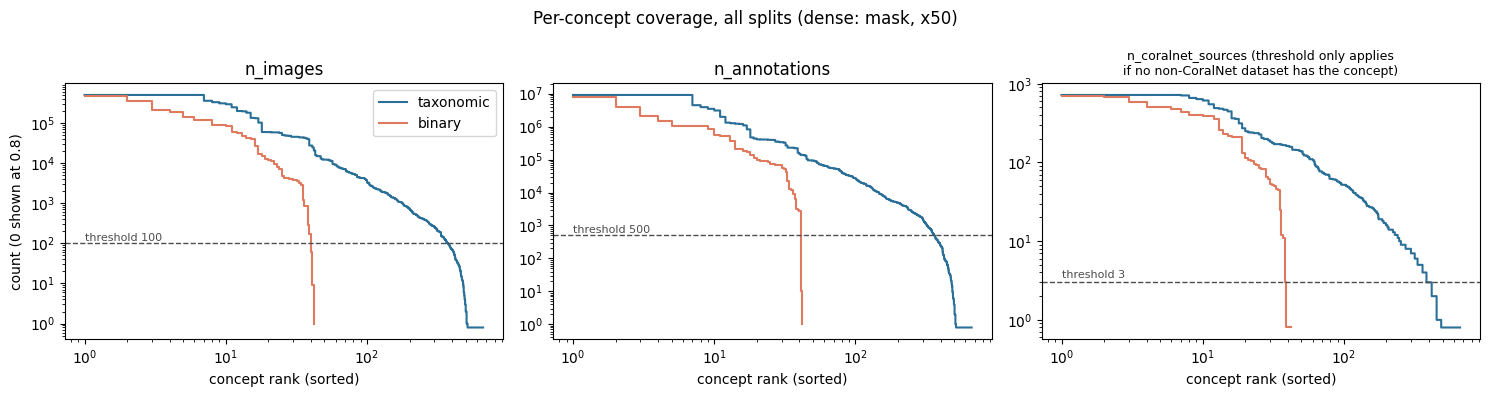

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, thr in zip(axes, ["n_images", "n_annotations", "n_coralnet_sources"],
                        [MIN_IMAGES, MIN_ANNOTATIONS, MIN_CORALNET_SOURCES]):
    for kind, color in [("taxonomic", "#2a6f97"), ("binary", "#e07a5f")]:
        v = np.sort(stats.loc[stats.kind == kind, col].to_numpy())[::-1]
        ax.step(np.arange(1, len(v) + 1), np.maximum(v, 0.8), where="post", label=kind, color=color)
    ax.axhline(thr, color="0.3", ls="--", lw=1)
    ax.text(1, thr * 1.15, f"threshold {thr}", fontsize=8, color="0.3")
    ax.set_yscale("log"); ax.set_xscale("log")
    ax.set_xlabel("concept rank (sorted)"); ax.set_title(col)
axes[0].set_ylabel("count (0 shown at 0.8)")
axes[2].set_title("n_coralnet_sources (threshold only applies\nif no non-CoralNet dataset has the concept)", fontsize=9)
axes[0].legend()
fig.suptitle(f"Per-concept coverage, all splits (dense: {DENSE_ANNOTATION_UNIT}, x{DENSE_ANNOTATIONS_PER_MASK})")
fig.tight_layout()

## 4b. Threshold sweep

How many concepts would be removed at other thresholds? One threshold is varied at a time, with the other two kept at
their current values (100 images, 500 annotations, 3 CoralNet sources):

- **Images**: 30, 50, 100, 200 in total. The non-CoralNet exception scales with it at half the total
  (15, 25, 50, 100), as in the current 100 / 50 rule.
- **Annotations**: 100, 200, 500, 1000 (each dense mask with the concept counts as 50).
- **CoralNet sources**: 1, 2, 3, 5 (a concept in any non-CoralNet dataset always passes the source rule).

Each panel shows all splits and train only. The dashed gray line is the number of concepts with no annotations at
all, the floor that no threshold can go below.

In [22]:
IMAGE_GRID = [30, 50, 100, 200]
ANNOTATION_GRID = [100, 200, 500, 1000]
SOURCE_GRID = [1, 2, 3, 5]


def removed_under(st: pd.DataFrame, min_img=MIN_IMAGES, min_ann=MIN_ANNOTATIONS, min_cn_src=MIN_CORALNET_SOURCES,
                  min_noncn_img=None) -> pd.Series:
    # Boolean per concept: removed under the given thresholds (same rule structure as concept_stats).
    min_noncn_img = min_img / 2 if min_noncn_img is None else min_noncn_img
    ok_img = (st.n_images >= min_img) | (st.n_noncoralnet_images >= min_noncn_img)
    ok_ann = st.n_annotations >= min_ann
    ok_src = (st.n_other_datasets >= 1) | (st.n_coralnet_sources >= min_cn_src)
    return ~(ok_img & ok_ann & ok_src)


assert (removed_under(stats) == stats.removed).all()  # matches the current rule

sweep_rows = []
for data_name, st in [("all splits", stats), ("train only", train_stats)]:
    for param, grid in [("images", IMAGE_GRID), ("annotations", ANNOTATION_GRID), ("coralnet_sources", SOURCE_GRID)]:
        for v in grid:
            kw = {"images": {"min_img": v}, "annotations": {"min_ann": v}, "coralnet_sources": {"min_cn_src": v}}[param]
            rem = removed_under(st, **kw)
            for kind in ["taxonomic", "binary"]:
                m = st.kind == kind
                sweep_rows.append({"data": data_name, "param": param, "threshold": v, "kind": kind,
                                   "removed": int(rem[m].sum()), "kept": int((~rem[m]).sum()),
                                   "kept_genus": int((~rem[m] & (st["rank"] == "genus")).sum()),
                                   "kept_family": int((~rem[m] & (st["rank"] == "family")).sum()),
                                   "no_annotations": int(st.no_annotations[m].sum())})
sweep = pd.DataFrame(sweep_rows)
sweep.pivot_table(index=["param", "threshold"], columns=["kind", "data"], values="removed")

kind                           binary             taxonomic           
data                       all splits train only all splits train only
param            threshold                                            
annotations      100              2.0        2.0      312.0      328.0
                 200              2.0        2.0      313.0      329.0
                 500              2.0        2.0      339.0      355.0
                 1000             2.0        2.0      372.0      383.0
coralnet_sources 1                2.0        2.0      315.0      333.0
                 2                2.0        2.0      323.0      341.0
                 3                2.0        2.0      339.0      355.0
                 5                2.0        2.0      367.0      385.0
images           30               2.0        2.0      335.0      350.0
                 50               2.0        2.0      335.0      351.0
                 100              2.0        2.0      339.0      355.0
                 200              3.0        4.0      360.0      378.0

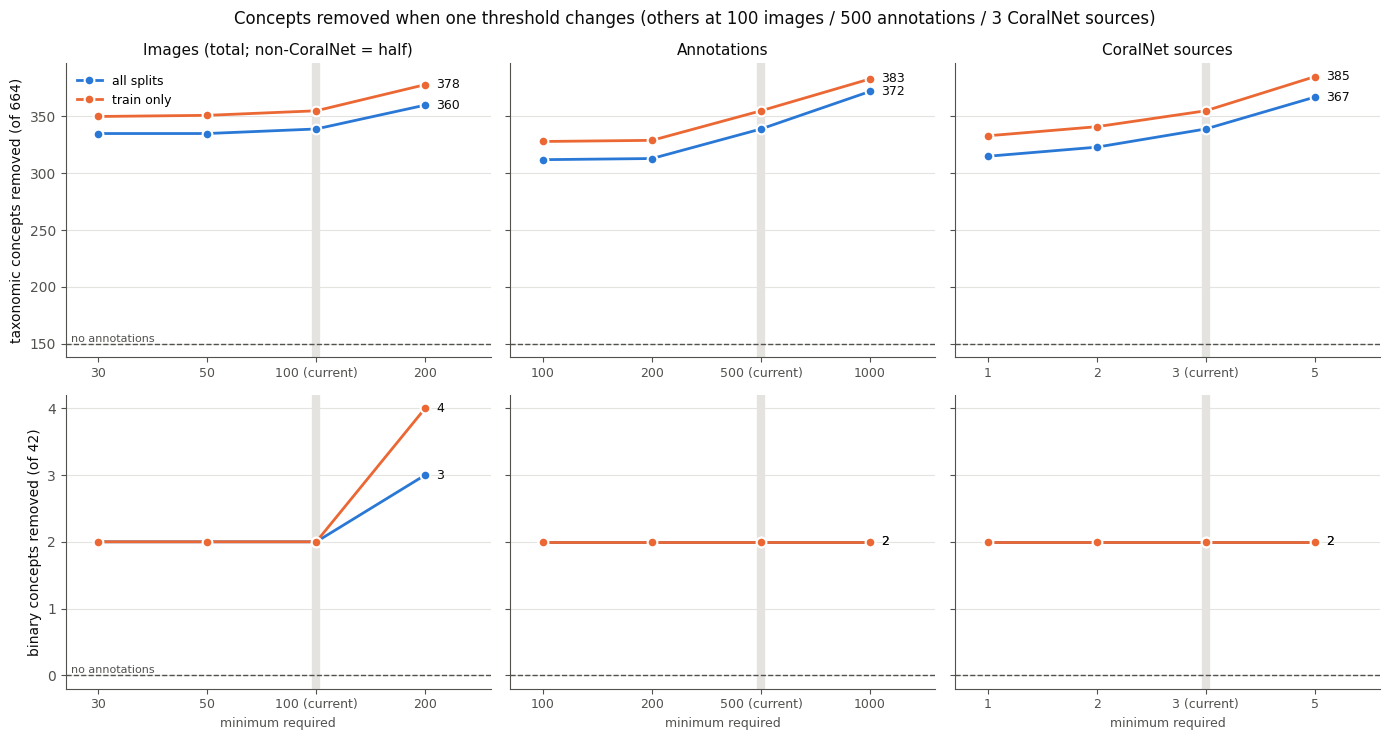

In [23]:
# Light-mode categorical slots 1-2 of the reference palette; text stays in ink colours.
SERIES = {"all splits": "#2a78d6", "train only": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
PARAMS = [("images", "Images (total; non-CoralNet = half)", MIN_IMAGES),
          ("annotations", "Annotations", MIN_ANNOTATIONS),
          ("coralnet_sources", "CoralNet sources", MIN_CORALNET_SOURCES)]

fig, axes = plt.subplots(2, 3, figsize=(14, 7.5), sharey="row")
for row, kind in enumerate(["taxonomic", "binary"]):
    n_total = int((stats.kind == kind).sum())
    for col, (param, title, current) in enumerate(PARAMS):
        ax = axes[row, col]
        sub = sweep[(sweep.param == param) & (sweep.kind == kind)]
        xs = sorted(sub.threshold.unique())
        pos = {v: i for i, v in enumerate(xs)}  # evenly spaced categories
        for data_name, color in SERIES.items():
            d = sub[sub.data == data_name].sort_values("threshold")
            x = [pos[v] for v in d.threshold]
            ax.plot(x, d.removed, color=color, lw=2, marker="o", ms=7, mec="white", mew=1.5, label=data_name,
                    zorder=3)
            ax.annotate(f"{d.removed.iloc[-1]}", (x[-1], d.removed.iloc[-1]), xytext=(8, 0),
                        textcoords="offset points", va="center", fontsize=9, color=INK)
        floor = sub.no_annotations.min()
        ax.axhline(floor, color=MUTED, ls="--", lw=1, zorder=1)
        ax.axvline(pos[current], color=GRID, lw=6, zorder=0)
        ax.set_xticks(range(len(xs)), [f"{v}" + (" (current)" if v == current else "") for v in xs], fontsize=9)
        ax.set_xlim(-0.3, len(xs) - 0.4)
        ax.grid(axis="y", color=GRID, lw=0.8)
        ax.yaxis.get_major_locator().set_params(integer=True)
        ax.set_axisbelow(True)
        for side in ["top", "right"]:
            ax.spines[side].set_visible(False)
        ax.spines["left"].set_color(MUTED)
        ax.spines["bottom"].set_color(MUTED)
        ax.tick_params(colors=MUTED)
        if row == 0:
            ax.set_title(title, fontsize=11, color=INK)
        if row == 1:
            ax.set_xlabel("minimum required", fontsize=9, color=MUTED)
        if col == 0:
            ax.set_ylabel(f"{kind} concepts removed (of {n_total})", fontsize=10, color=INK)
            ax.text(-0.25, floor, "no annotations", fontsize=8, color=MUTED, va="bottom")
axes[0, 0].legend(frameon=False, fontsize=9, loc="upper left")
fig.suptitle("Concepts removed when one threshold changes (others at 100 images / 500 annotations / 3 CoralNet sources)",
             fontsize=12, color=INK)
fig.tight_layout()

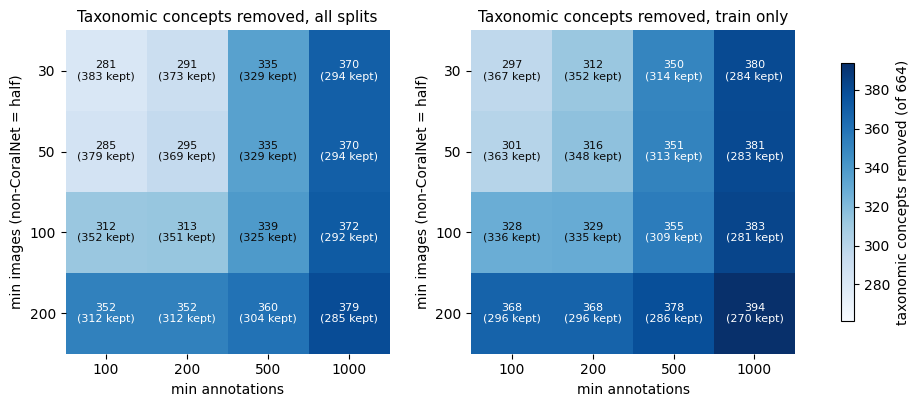

In [24]:
# Taxonomic concepts removed for every images x annotations combination (CoralNet sources fixed at 3)
heat = {}
for data_name, st in [("all splits", stats), ("train only", train_stats)]:
    tax_st = st[st.kind == "taxonomic"]
    heat[data_name] = pd.DataFrame([[int(removed_under(tax_st, min_img=i, min_ann=a).sum()) for a in ANNOTATION_GRID]
                                    for i in IMAGE_GRID], index=IMAGE_GRID, columns=ANNOTATION_GRID)
vmin = min(g.to_numpy().min() for g in heat.values()) - 20
vmax = max(g.to_numpy().max() for g in heat.values())
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (data_name, st) in zip(axes, [("all splits", stats), ("train only", train_stats)]):
    tax_st = st[st.kind == "taxonomic"]
    grid = heat[data_name]
    im = ax.imshow(grid.to_numpy(), cmap="Blues", vmin=vmin, vmax=vmax)
    for r, i in enumerate(IMAGE_GRID):
        for c, a in enumerate(ANNOTATION_GRID):
            v = grid.loc[i, a]
            ax.text(c, r, f"{v}\n({len(tax_st) - v} kept)", ha="center", va="center", fontsize=8,
                    color="white" if v > vmin + 0.6 * (vmax - vmin) else INK)
    ax.set_xticks(range(len(ANNOTATION_GRID)), ANNOTATION_GRID)
    ax.set_yticks(range(len(IMAGE_GRID)), IMAGE_GRID)
    ax.set_xlabel("min annotations"); ax.set_ylabel("min images (non-CoralNet = half)")
    ax.set_title(f"Taxonomic concepts removed, {data_name}", fontsize=11)
    for s in ax.spines.values():
        s.set_visible(False)
fig.colorbar(im, ax=axes, shrink=0.8, label="taxonomic concepts removed (of 664)")

In [25]:
# Kept taxonomic concepts per rank for each setting in the sweep (all splits)
rank_rows = []
for param, grid in [("images", IMAGE_GRID), ("annotations", ANNOTATION_GRID), ("coralnet_sources", SOURCE_GRID)]:
    for v in grid:
        kw = {"images": {"min_img": v}, "annotations": {"min_ann": v}, "coralnet_sources": {"min_cn_src": v}}[param]
        kept = ~removed_under(stats, **kw) & (stats.kind == "taxonomic")
        row = stats.loc[kept, "rank"].value_counts().reindex(TAXONOMIC_CONCEPTS, fill_value=0).to_dict()
        rank_rows.append({"param": param, "threshold": v, **row, "total": int(kept.sum())})
pd.DataFrame(rank_rows).set_index(["param", "threshold"])

kingdom  phylum  class  order  family  genus  total
param            threshold                                                     
images           30               5      15     20     48      95    146    329
                 50               5      15     20     48      95    146    329
                 100              5      15     20     48      94    143    325
                 200              5      15     20     46      86    132    304
annotations      100              5      15     21     52     101    158    352
                 200              5      15     21     51     101    158    351
                 500              5      15     20     48      94    143    325
                 1000             5      15     19     45      82    126    292
coralnet_sources 1                5      15     20     49     102    158    349
                 2                5      15     20     49     100    152    341
                 3                5      15     20     48      94    143    325
                 5                5      15     19     42      87    129    297

In [26]:
# Which binary concepts flip across the sweep?
flip_rows = []
for param, grid in [("images", IMAGE_GRID), ("annotations", ANNOTATION_GRID), ("coralnet_sources", SOURCE_GRID)]:
    for v in grid:
        kw = {"images": {"min_img": v}, "annotations": {"min_ann": v}, "coralnet_sources": {"min_cn_src": v}}[param]
        for data_name, st in [("all splits", stats), ("train only", train_stats)]:
            rem = removed_under(st, **kw) & (st.kind == "binary")
            flip_rows.append({"param": param, "threshold": v, "data": data_name,
                              "removed_binary": ", ".join(st.index[rem])})
pd.DataFrame(flip_rows).pivot_table(index=["param", "threshold"], columns="data", values="removed_binary",
                                    aggfunc="first")

data                                               all splits                                train only
param            threshold                                                                             
annotations      100                       tubular, cup_coral                        tubular, cup_coral
                 200                       tubular, cup_coral                        tubular, cup_coral
                 500                       tubular, cup_coral                        tubular, cup_coral
                 1000                      tubular, cup_coral                        tubular, cup_coral
coralnet_sources 1                         tubular, cup_coral                        tubular, cup_coral
                 2                         tubular, cup_coral                        tubular, cup_coral
                 3                         tubular, cup_coral                        tubular, cup_coral
                 5                         tubular, cup_coral                        tubular, cup_coral
images           30                        tubular, cup_coral                        tubular, cup_coral
                 50                        tubular, cup_coral                        tubular, cup_coral
                 100                       tubular, cup_coral                        tubular, cup_coral
                 200        tubular, cup_coral, water surface  tubular, cup_coral, trash, water surface

## 5. Sensitivity checks

- **Dense annotation unit.** How removal changes with 1 or 500 annotations per dense mask instead of 50, when dense
  masks count as pixels (pixel counts pass 500 easily), or when they are left out entirely (only point annotations
  count, as in the MERMAID label selection).
- **Concept table.** The same analysis with the other concept tables in `configs/`.

In [27]:
rows_out = []
for unit, per_mask in [("mask", 50), ("mask", 1), ("mask", 500), ("pixels", None), ("exclude", None)]:
    s = concept_stats(counts, K, info, unit, per_mask or DENSE_ANNOTATIONS_PER_MASK)
    label = f"mask x{per_mask}" if unit == "mask" else unit
    for kind, g in s.groupby("kind"):
        rows_out.append({"dense_unit": label, "kind": kind, "n_concepts": len(g),
                         "no_annotations": int(g.no_annotations.sum()), "removed": int(g.removed.sum()),
                         "kept": int((~g.removed).sum())})
pd.DataFrame(rows_out).set_index(["dense_unit", "kind"])

n_concepts  no_annotations  removed  kept
dense_unit kind                                                
mask x50   binary             42               0        2    40
           taxonomic         664             150      339   325
mask x1    binary             42               0        4    38
           taxonomic         664             150      339   325
mask x500  binary             42               0        2    40
           taxonomic         664             150      339   325
pixels     binary             42               0        2    40
           taxonomic         664             150      339   325
exclude    binary             42               3        5    37
           taxonomic         664             152      343   321

In [28]:
rows_out = []
for csv in ["class_to_concepts.csv", "class_to_concepts_v1_aligned.csv", "class_to_concepts_v2.csv"]:
    _, _, info_c, matrix_c = build_concepts(REPO / "configs" / csv)
    s = concept_stats(counts, matrix_c(key_pairs), info_c, DENSE_ANNOTATION_UNIT)
    for kind, g in s.groupby("kind"):
        rows_out.append({"concept_csv": csv, "kind": kind, "n_concepts": len(g),
                         "no_annotations": int(g.no_annotations.sum()), "removed": int(g.removed.sum()),
                         "kept": int((~g.removed).sum())})
pd.DataFrame(rows_out).set_index(["concept_csv", "kind"])

n_concepts  no_annotations  removed  kept
concept_csv                      kind                                                
class_to_concepts.csv            binary             39               0        2    37
                                 taxonomic         664             150      339   325
class_to_concepts_v1_aligned.csv binary             42               0        2    40
                                 taxonomic         664             150      339   325
class_to_concepts_v2.csv         binary             42               0        2    40
                                 taxonomic         664             150      339   325

## 6. Evaluation coverage of the kept concepts

The kept set is decided on the **train splits only**: >= 100 images (or >= 50 outside CoralNet), >= 500 annotations
(each dense mask with the concept counts as 50), and >= 3 CoralNet sources (or any non-CoralNet dataset).

For each kept concept this section counts its support in the **evaluation splits**, i.e. every non-train split of
`data_config_final_768`: CoralNet test, Coralscapes v2 test, Pacific Labeled Corals (val) and Benthos (val). Annotations
are counted the same way as above (points, and 50 per dense mask).

To summarise, each kept concept is put into one band (`EVAL_MIN_ANNOTATIONS`, `EVAL_MIN_IMAGES` set the cutoff):

- **none**: no True annotation in any evaluation split; the concept cannot be evaluated.
- **thin**: some support, but below 30 annotations or 10 images; metrics would be very noisy.
- **evaluable**: >= 30 annotations and >= 10 images.

The cutoff is a judgement call, so the tables also show the counts at other cutoffs.

In [29]:
EVAL_MIN_ANNOTATIONS, EVAL_MIN_IMAGES = 30, 10
EVAL_DATASETS = sorted(counts.loc[counts.split != "train", "dataset"].unique())

kept_train = ~train_stats.removed
eval_counts = counts[counts.split != "train"]
eval_stats = concept_stats(eval_counts, K, info, DENSE_ANNOTATION_UNIT)

cov = train_stats.loc[kept_train, ["kind", "rank", "in_current_model", "n_annotations", "n_images"]].rename(
    columns={"n_annotations": "train_annotations", "n_images": "train_images"})
cov["eval_annotations"] = eval_stats.loc[cov.index, "n_annotations"]
cov["eval_images"] = eval_stats.loc[cov.index, "n_images"]
cov["eval_coralnet_sources"] = eval_stats.loc[cov.index, "n_coralnet_sources"]
for ds in EVAL_DATASETS:
    ds_stats = concept_stats(eval_counts[eval_counts.dataset == ds], K, info, DENSE_ANNOTATION_UNIT)
    cov[f"images_{ds}"] = ds_stats.loc[cov.index, "n_images"]
cov["band"] = np.select(
    [cov.eval_annotations == 0,
     (cov.eval_annotations < EVAL_MIN_ANNOTATIONS) | (cov.eval_images < EVAL_MIN_IMAGES)],
    ["none", "thin"], "evaluable")
print(f"Kept on train: {len(cov)} concepts ({cov.kind.value_counts().to_dict()})")
print("Evaluation splits:", counts.loc[counts.split != "train"].groupby(["dataset", "split"]).image_id.nunique().to_dict())
pd.crosstab(cov.kind, cov.band, margins=True)[["none", "thin", "evaluable", "All"]]

Kept on train: 349 concepts ({'taxonomic': 309, 'binary': 40})
Evaluation splits: {('benthos_yuval', 'val'): 48, ('coralnet', 'test'): 51026, ('coralscapes_v2', 'test'): 473, ('pacific_labeled_corals', 'val'): 4419}


band,none,thin,evaluable,All
kind,,,,
binary,0,1,39,40
taxonomic,52,49,208,309
All,52,50,247,349


In [30]:
# By rank
order = [*TAXONOMIC_CONCEPTS, "binary"]
by_rank = pd.crosstab(cov["rank"], cov.band).reindex(index=order, columns=["none", "thin", "evaluable"], fill_value=0)
by_rank["kept"] = by_rank.sum(axis=1)
by_rank["pct_evaluable"] = (100 * by_rank.evaluable / by_rank.kept).round(1)
by_rank

band,none,thin,evaluable,kept,pct_evaluable
rank,,,,,
kingdom,0,0,5,5,100.0
phylum,0,1,14,15,93.3
class,1,1,18,20,90.0
order,10,11,26,47,55.3
family,17,17,56,90,62.2
genus,24,19,89,132,67.4
binary,0,1,39,40,97.5


In [31]:
# Sensitivity: number of kept concepts meeting other evaluation cutoffs (annotations AND images)
rows = []
for min_ann, min_img in [(1, 1), (10, 5), (30, 10), (50, 20), (100, 30), (500, 100)]:
    ok = (cov.eval_annotations >= min_ann) & (cov.eval_images >= min_img)
    rows.append({"cutoff": f">= {min_ann} ann & >= {min_img} img",
                 **{k: int(ok[cov.kind == k].sum()) for k in ["taxonomic", "binary"]}})
pd.DataFrame(rows).set_index("cutoff").assign(
    taxonomic_of=int((cov.kind == "taxonomic").sum()), binary_of=int((cov.kind == "binary").sum()))

,taxonomic,binary,taxonomic_of,binary_of
cutoff,,,,
>= 1 ann & >= 1 img,257,40,309,40
>= 10 ann & >= 5 img,227,40,309,40
>= 30 ann & >= 10 img,208,39,309,40
>= 50 ann & >= 20 img,197,38,309,40
>= 100 ann & >= 30 img,176,36,309,40
>= 500 ann & >= 100 img,136,33,309,40


In [32]:
# Which evaluation datasets cover the kept concepts? (concepts with >= 1 / >= EVAL_MIN_IMAGES images in each)
ds_cov = pd.DataFrame({
    ds: {
        "taxonomic >=1 img": int(((cov[f"images_{ds}"] >= 1) & (cov.kind == "taxonomic")).sum()),
        f"taxonomic >={EVAL_MIN_IMAGES} img": int(((cov[f"images_{ds}"] >= EVAL_MIN_IMAGES) & (cov.kind == "taxonomic")).sum()),
        "binary >=1 img": int(((cov[f"images_{ds}"] >= 1) & (cov.kind == "binary")).sum()),
        f"binary >={EVAL_MIN_IMAGES} img": int(((cov[f"images_{ds}"] >= EVAL_MIN_IMAGES) & (cov.kind == "binary")).sum()),
    } for ds in EVAL_DATASETS}).T
img_cols = [f"images_{ds}" for ds in EVAL_DATASETS]
only_cn = (cov[img_cols].drop(columns="images_coralnet").sum(axis=1) == 0) & (cov.images_coralnet > 0)
print(f"Kept concepts whose only evaluation support is CoralNet test: {int(only_cn.sum())} of {len(cov)}")
ds_cov

Kept concepts whose only evaluation support is CoralNet test: 199 of 349


,taxonomic >=1 img,taxonomic >=10 img,binary >=1 img,binary >=10 img
benthos_yuval,13,13,5,5
coralnet,254,213,37,37
coralscapes_v2,58,45,27,25
pacific_labeled_corals,35,35,11,11


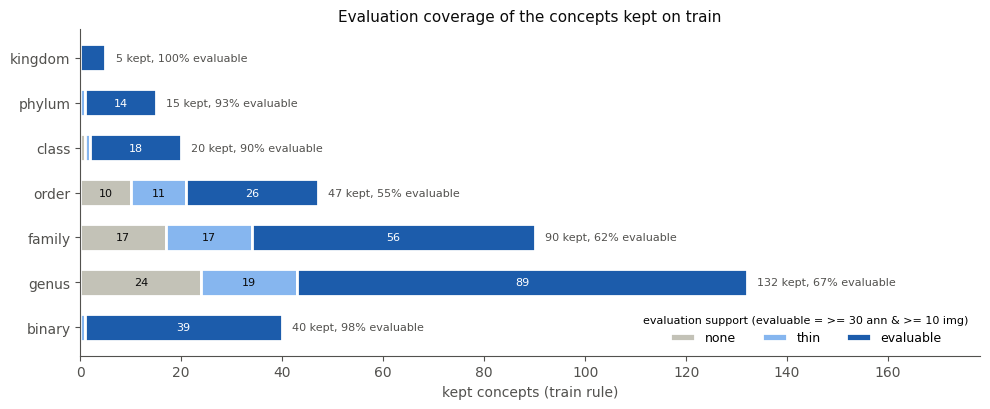

In [33]:
BAND_COLORS = {"none": "#c3c2b7", "thin": "#86b6ef", "evaluable": "#1c5cab"}  # neutral + ordinal blue steps
fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(order))[::-1]
left = np.zeros(len(order))
for band, color in BAND_COLORS.items():
    vals = by_rank[band].to_numpy()
    ax.barh(y, vals, left=left, color=color, height=0.6, edgecolor="white", linewidth=2, label=band)
    for yi, l, v in zip(y, left, vals):
        if v >= 6:
            ax.text(l + v / 2, yi, str(v), ha="center", va="center", fontsize=8,
                    color="white" if band == "evaluable" else INK)
    left += vals
for yi, tot, pct in zip(y, by_rank.kept, by_rank.pct_evaluable):
    ax.text(tot + 2, yi, f"{tot} kept, {pct:.0f}% evaluable", va="center", fontsize=8, color=MUTED)
ax.set_yticks(y, order)
ax.set_xlim(0, by_rank.kept.max() * 1.35)
ax.set_xlabel("kept concepts (train rule)", color=MUTED)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.spines["left"].set_color(MUTED); ax.spines["bottom"].set_color(MUTED); ax.tick_params(colors=MUTED)
ax.legend(frameon=False, ncol=3, loc="lower right", fontsize=9,
          title=f"evaluation support (evaluable = >= {EVAL_MIN_ANNOTATIONS} ann & >= {EVAL_MIN_IMAGES} img)",
          title_fontsize=8)
ax.set_title("Evaluation coverage of the concepts kept on train", fontsize=11, color=INK)
fig.tight_layout()

In [34]:
# Kept concepts with no or thin evaluation support
cols = ["kind", "rank", "band", "train_annotations", "train_images", "eval_annotations", "eval_images",
        "eval_coralnet_sources", *img_cols]
weak = cov[cov.band != "evaluable"][cols].copy()
weak["rank"] = pd.Categorical(weak["rank"], order, ordered=True)
weak.sort_values(["band", "rank", "train_annotations"], ascending=[True, True, False])

,kind,rank,band,train_annotations,train_images,eval_annotations,eval_images,eval_coralnet_sources,images_benthos_yuval,images_coralnet,images_coralscapes_v2,images_pacific_labeled_corals
class__gymnolaemata,taxonomic,class,none,3980,308,0,0,0,0,0,0,0
order__balanomorpha,taxonomic,order,none,39676,1042,0,0,0,0,0,0,0
order__mytilida,taxonomic,order,none,27662,1405,0,0,0,0,0,0,0
order__stolidobranchia,taxonomic,order,none,8690,428,0,0,0,0,0,0,0
order__phlebobranchia,taxonomic,order,none,4089,202,0,0,0,0,0,0,0
order__cheilostomatida,taxonomic,order,none,3980,308,0,0,0,0,0,0,0
order__verongiida,taxonomic,order,none,3862,400,0,0,0,0,0,0,0
order__arbacioida,taxonomic,order,none,3002,862,0,0,0,0,0,0,0
order__sessilia,taxonomic,order,none,2440,103,0,0,0,0,0,0,0
order__forcipulatida,taxonomic,order,none,2321,286,0,0,0,0,0,0,0


In [35]:
# Binary concepts: evaluation support for every kept one
cov[cov.kind == "binary"][["in_current_model", "band", "train_annotations", "eval_annotations", "eval_images",
                           *img_cols]].sort_values("eval_annotations", ascending=False)

,in_current_model,band,train_annotations,eval_annotations,eval_images,images_benthos_yuval,images_coralnet,images_coralscapes_v2,images_pacific_labeled_corals
algae,True,evaluable,7436378,671117,43480,45,38992,247,4196
live,True,evaluable,3539925,365266,36074,48,32123,442,3461
sand,True,evaluable,1888070,224435,20291,48,19626,272,345
hard_substrate,True,evaluable,865287,177910,18516,48,17788,439,241
calcifying,True,evaluable,1330430,165129,22004,40,20613,0,1351
branching,True,evaluable,954389,116136,8842,0,7760,360,722
macroalgae,True,evaluable,916279,97690,16203,0,14202,0,2001
rubble,False,evaluable,758507,85805,11438,0,11198,240,0
massive,True,evaluable,994941,59163,11303,0,10904,399,0
submassive,True,evaluable,489295,47333,6778,0,6389,389,0


## Summary

In [36]:
rs = removal_summary(stats)
for kind in ["taxonomic", "binary"]:
    r = rs.loc[kind]
    print(f"{kind:>9}: {r.n_concepts} concepts | {r.no_annotations} with no True annotations | "
          f"{r['removed(any)']} removed by (>= {MIN_IMAGES} images or >= {MIN_NONCORALNET_IMAGES} non-CoralNet images) / "
          f">= {MIN_ANNOTATIONS} annotations / "
          f"(>= 1 non-CoralNet dataset or >= {MIN_CORALNET_SOURCES} CoralNet sources) "
          f"({r.removed_with_annotations} of them do have annotations) | {r.kept} kept")
print(f"(concept table: {CONCEPT_CSV.name}, dense: {DENSE_ANNOTATION_UNIT} x{DENSE_ANNOTATIONS_PER_MASK}, all splits of "
      "data_config_final_768)")
print("New binary concepts (not in current model):")
print(stats.loc[~stats.in_current_model, ["n_annotations", "n_images", "n_noncoralnet_images", "n_sources", "removed"]])

taxonomic: 664 concepts | 150 with no True annotations | 339 removed by (>= 100 images or >= 50 non-CoralNet images) / >= 500 annotations / (>= 1 non-CoralNet dataset or >= 3 CoralNet sources) (189 of them do have annotations) | 325 kept
   binary: 42 concepts | 0 with no True annotations | 2 removed by (>= 100 images or >= 50 non-CoralNet images) / >= 500 annotations / (>= 1 non-CoralNet dataset or >= 3 CoralNet sources) (2 of them do have annotations) | 40 kept
(concept table: class_to_concepts_v2.csv, dense: mask x50, all splits of data_config_final_768)
New binary concepts (not in current model):
               n_annotations  n_images  n_noncoralnet_images  n_sources  removed
rubble                840062     87985                 11528        363    False
water surface           3050        61                    61          1    False
water column           42500       850                   850          1    False
